In [1]:
!git clone -b eda-numericas https://github.com/CaioC11/projeto-itbi-cin0208.git
%cd projeto-itbi-cin0208

Cloning into 'projeto-itbi-cin0208'...
remote: Enumerating objects: 21, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (18/18), done.
remote: Total 21 (delta 2), reused 14 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (21/21), 418.84 KiB | 5.17 MiB/s, done.
Resolving deltas: 100% (2/2), done.
/content/projeto-itbi-cin0208


In [3]:
import os, sys, subprocess

#baixando o repositório
if 'google.colab' in sys.modules and not os.path.exists('projeto-itbi-cin0208'):
    subprocess.run(['git', 'clone', '-b', 'eda-numericas',
                    'https://github.com/CaioC11/projeto-itbi-cin0208.git'], check=True)

if os.path.isdir('projeto-itbi-cin0208'):
    os.chdir('projeto-itbi-cin0208')
elif os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

sys.path.insert(0, os.getcwd())
print('Pasta atual:', os.getcwd())

Pasta atual: /content/projeto-itbi-cin0208/projeto-itbi-cin0208


In [4]:
#1.Carregamento dos dados
import pandas as pd
import matplotlib.pyplot as plt
from src.carregar_dados import carregar_dados

df = carregar_dados()
print(df.shape)
print(df[['latitude', 'longitude']].dtypes)

(16318, 22)
latitude     float64
longitude    float64
dtype: object


In [5]:
#2.Quais colunas são numéricas de vdd
colunas_numericas = df.select_dtypes(include='number').columns.tolist()

print(len(colunas_numericas))
print(colunas_numericas)

11
['numero', 'valor_avaliacao', 'ano_construcao', 'area_terreno', 'area_construida', 'fracao_ideal', 'sfh', 'cod_logradouro', 'latitude', 'longitude', 'ano']


In [6]:
alvo = 'valor_avaliacao'
identificadores = ['numero', 'cod_logradouro']
constantes = ['ano']
medidas = [c for c in colunas_numericas if c not in [alvo] + identificadores + constantes]

print(medidas)
print(df[colunas_numericas].nunique().sort_values())
print(df['logradouro'].nunique(), df['cod_logradouro'].nunique())

['ano_construcao', 'area_terreno', 'area_construida', 'fracao_ideal', 'sfh', 'latitude', 'longitude']
ano                   1
ano_construcao       87
numero             1395
cod_logradouro     1455
fracao_ideal       2934
area_terreno       3071
longitude          3644
sfh                3661
latitude           3676
valor_avaliacao    5195
area_construida    5304
dtype: int64
1460 1455


Das 11 colunas numericas, só 7 são medidas reais, já que **valor_avaliação** é o alvo, **numero e cod_logradouro** são só identificadores e o **ano** é igual pra todo mundo.

In [8]:
#3.Estatísticas descritivas
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

tabela = df[medidas].describe().T
tabela['zeros'] = (df[medidas] == 0).sum()
tabela['nulos'] = df[medidas].isna().sum()
tabela

,count,mean,std,min,25%,50%,75%,max,zeros,nulos
ano_construcao,"16,318.00","2,006.19",20.48,"1,939.00","1,994.00","2,013.00","2,024.00","2,025.00",0,0
area_terreno,"16,318.00","7,354.38","25,116.46",0.00,"1,016.00","1,890.00","4,500.00","299,081.00",86,0
area_construida,"16,318.00",148.98,547.48,5.77,65.07,89.96,142.23,"31,558.00",0,0
fracao_ideal,"16,318.00",0.10,0.27,0.00,0.00,0.01,0.03,1.00,1,0
sfh,"16,318.00","84,181.78","146,746.62",0.00,0.00,0.00,"155,609.96","4,000,000.00",10616,0
latitude,"10,468.00",-8.08,0.04,-8.15,-8.12,-8.06,-8.04,-8.00,0,5850
longitude,"10,468.00",-34.90,0.02,-34.99,-34.91,-34.90,-34.89,-34.87,0,5850


In [9]:
#1. que tipo de imóvel tem terreno zero?
print(df[df['area_terreno'] == 0]['tipo_imovel'].value_counts())

#2. terreno "efetivo" de cada unidade
terreno_efetivo = df['area_terreno'] * df['fracao_ideal']
print(terreno_efetivo.describe())

tipo_imovel
Casa                   78
Apartamento             5
Edificação Especial     2
Industria               1
Name: count, dtype: int64
count   16,318.00
mean       110.63
std        997.87
min          0.00
25%         15.03
50%         25.23
75%         47.96
max     54,900.00
dtype: float64


Na base crua (16.318 linhas), nenhuma das 7 medidas tem ano impossível. As anomalias são a: **area_terreno** igual a zero em 86 linhas (0,5%), das quais 78 são casas, o que indica dado ausente registrado como zero; **fracao_ideal** igual a zero em 1 linha; **sfh** igual a zero em 65% das linhas; e **latitude/longitude** ausentes em 36% (5.850 linhas, sempre juntas). Em **area_terreno, area_construida, fracao_ideal e sfh** a média fica muito acima da mediana (assimetria à direita). Em geral a area_terreno representa o lote inteiro e a  fracao_ideal a é a parte de cada unidade usada pra construção do imovel: o produto das duas tem mediana de 25 m², contra 1.890 m² do terreno bruto.

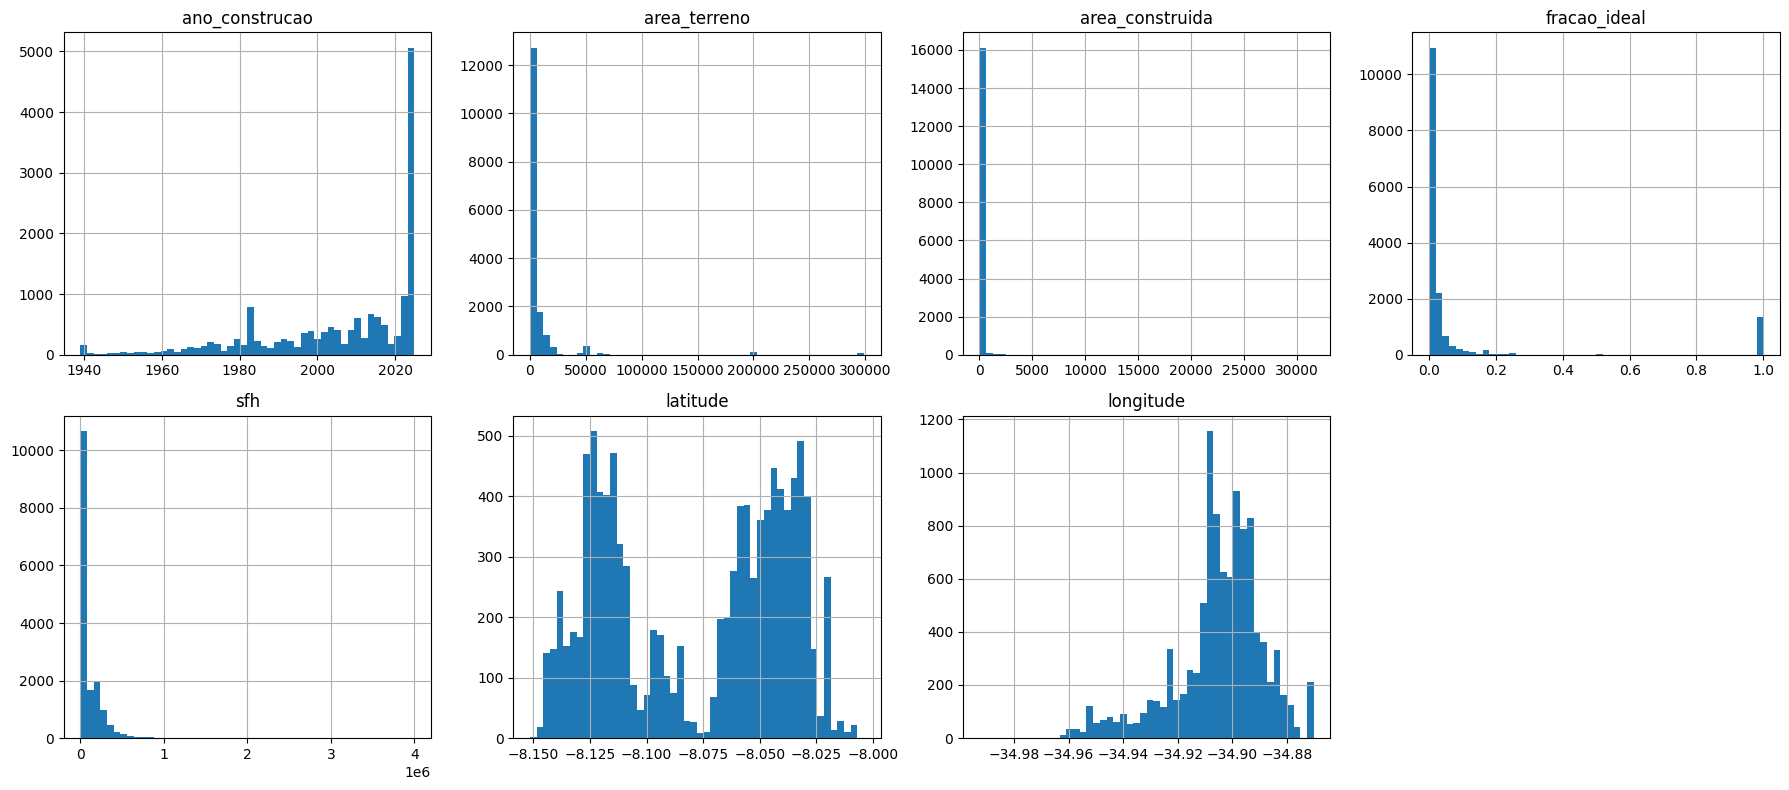

In [10]:
#4.Histogramas
fig, eixos = plt.subplots(2, 4, figsize=(18, 8))
eixos = eixos.flatten()

for i, col in enumerate(medidas):
    df[col].dropna().hist(bins=50, ax=eixos[i])
    eixos[i].set_title(col)

eixos[-1].axis('off')
plt.tight_layout()
plt.show()

In [11]:
#1.pico de 2024/2025 e a barra de 1939
print((df['ano_construcao'] >= 2024).mean())
print((df['ano_construcao'] == 1939).sum())

#2.quem tem fração ideal igual a 1?
print((df['fracao_ideal'] == 1).sum())
print(df.loc[df['fracao_ideal'] == 1, 'tipo_imovel'].value_counts().head())

0.31020958450790537
148
1352
tipo_imovel
Casa                      1009
Edificação Especial        120
Loja                       114
Galpão                      56
Instituição Financeira      11
Name: count, dtype: int64


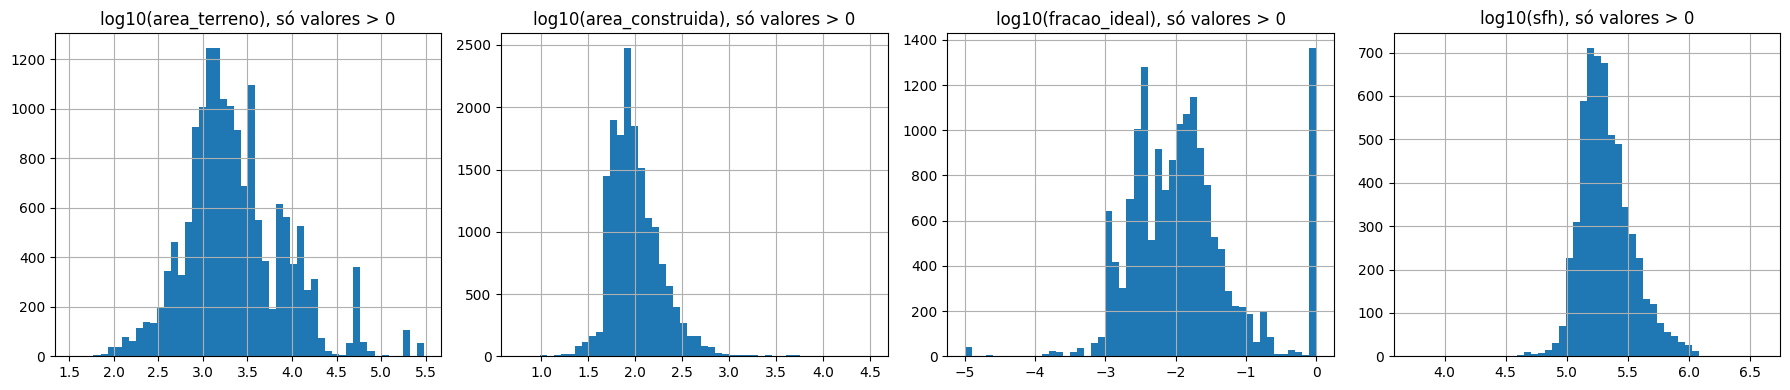

In [12]:
import numpy as np

assimetricas = ['area_terreno', 'area_construida', 'fracao_ideal', 'sfh']

fig, eixos = plt.subplots(1, 4, figsize=(18, 4))

for ax, col in zip(eixos, assimetricas):
    positivos = df.loc[df[col] > 0, col]
    np.log10(positivos).hist(bins=50, ax=ax)
    ax.set_title(f'log10({col}), só valores > 0')

plt.tight_layout()
plt.show()

**area_terreno, area_construida, fracao_ideal e sfh** têm forte assimetria na direita: quase todos os imóveis estão perto de zero e poucos valores enormes esticam o eixo. **ano_construcao** tem um pico em 2024 e 2025 (cerca de 30% da base). **fracao_ideal** tem dois grupos, um perto de zero (unidades de prédio) e um em 1,0 (imóvel que ocupa o lote inteiro). **latitude e longitude** mostram dois aglomerados geográficos distintos.

In [ ]:
## 5. Correlação com o alvo

In [ ]:
## 6. Escalas e por que o kNN exige normalização

In [ ]:
## 7. Achados e variáveis que ficam